<a href="https://colab.research.google.com/github/n-schiozer/met_comp_economistas_unesp/blob/main/Aula_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 10 — Análise exploratória de dados econômicos com Python
**Métodos Computacionais em Economia · UNESP · 10/11/2026**

**Pergunta da aula:** o que os dados do Banco Mundial revelam sobre a distribuição e a evolução das taxas reais de juros entre países?

Trabalharemos com **Pandas** e **Matplotlib**: descrições estatísticas, distribuições, valores extremos, séries anuais, gráficos de dispersão e correlações. Os dados são reais e carregados pela API do **World Development Indicators (WDI)**.

> **Atenção:** o indicador de juros reais (`FR.INR.RINR`) é uma taxa real de empréstimos ajustada pela inflação, **não a taxa de política monetária**. O indicador de prêmio de risco (`FR.INR.RISK`) é um spread bancário, **não o risco soberano EMBI**.

## 1. Bibliotecas e coleta de dados

- `requests` consulta a API do Banco Mundial pela internet;
- `pandas` organiza e manipula tabelas;
- `matplotlib.pyplot` personaliza e mostra gráficos.



In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.2f}".format)

### 1.1 Indicadores utilizados

| Nome no notebook | Indicador WDI | Unidade / interpretação |
|---|---|---|
| `juros_real_pct` | `FR.INR.RINR` | Taxa real de empréstimos (%) |
| `inflacao_anual_pct` | `FP.CPI.TOTL.ZG` | Inflação anual ao consumidor (%) |
| `desemprego_pct` | `SL.UEM.TOTL.ZS` | Desemprego (% força de trabalho) |
| `crescimento_pc_pct` | `NY.GDP.PCAP.KD.ZG` | Crescimento real do PIB per capita (%) |
| `pib_per_capita_usd` | `NY.GDP.PCAP.CD` | PIB per capita (US$ correntes) |
| `investimento_pct_pib` | `NE.GDI.FTOT.ZS` | Formação bruta de capital fixo (% PIB) |
| `spread_bancario_pp` | `FR.INR.RISK` | Prêmio de risco de empréstimos (pontos percentuais) |
| `rendas_recursos_pct_pib` | `NY.GDP.TOTL.RT.ZS` | Rendas de recursos naturais (% PIB) |

A cobertura varia entre países e períodos. Para esta aula, utilizaremos **2000–2024**, mesmo que a API ofereça anos mais recentes.

In [3]:
indicadores = {
    "FR.INR.RINR": "juros_real_pct",
    "FP.CPI.TOTL.ZG": "inflacao_anual_pct",
    "SL.UEM.TOTL.ZS": "desemprego_pct",
    "NY.GDP.PCAP.KD.ZG": "crescimento_pc_pct",
    "NY.GDP.PCAP.CD": "pib_per_capita_usd",
    "NE.GDI.FTOT.ZS": "investimento_pct_pib",
    "FR.INR.RISK": "spread_bancario_pp",
    "NY.GDP.TOTL.RT.ZS": "rendas_recursos_pct_pib"
}

ano_inicial, ano_final = 2000, 2024

### 1.2 Função de consulta à API

Função preparada para a coleta direto de dados do Banco Mundla. A API responde em formato JSON.

In [4]:
def consultar_banco_mundial(url, params=None):
    """Consulta a API v2 do Banco Mundial e reúne todas as páginas."""
    parametros = {"format": "json", "per_page": 10000}
    if params is not None:
        parametros.update(params)

    registros = []
    pagina = 1

    while True:
        parametros["page"] = pagina
        try:
            resposta = requests.get(url, params=parametros, timeout=40)
            resposta.raise_for_status()
            conteudo = resposta.json()
        except (requests.RequestException, ValueError) as erro:
            raise RuntimeError(f"Falha ao consultar o Banco Mundial: {erro}") from erro

        if not isinstance(conteudo, list) or len(conteudo) < 2 or not isinstance(conteudo[1], list):
            raise RuntimeError(f"Resposta inesperada da API: {str(conteudo)[:300]}")

        registros.extend(conteudo[1])
        total_paginas = int(conteudo[0].get("pages", 1))
        if pagina >= total_paginas:
            break
        pagina += 1

    return registros

### 1.3 Baixar indicadores e metadados dos países


In [5]:
# Metadados: nomes e regiões dos países
metadados = consultar_banco_mundial("https://api.worldbank.org/v2/country")
paises = pd.DataFrame([
    {
        "codigo_pais": item["id"],
        "pais": item["name"],
        "regiao": item["region"]["value"]
    }
    for item in metadados
    if item.get("region", {}).get("value") not in ("Aggregates", "")
])

print("Países/economias na lista:", len(paises))
display(paises.head())

Países/economias na lista: 217


,codigo_pais,pais,regiao
0,ABW,Aruba,Latin America & Caribbean
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
2,AGO,Angola,Sub-Saharan Africa
3,ALB,Albania,Europe & Central Asia
4,AND,Andorra,Europe & Central Asia


In [6]:
# Consultar os oito indicadores (uma série por vez)
partes = []
for codigo_indicador, nome_coluna in indicadores.items():
    url = f"https://api.worldbank.org/v2/country/all/indicator/{codigo_indicador}"
    registros = consultar_banco_mundial(
        url,
        params={"date": f"{ano_inicial}:{ano_final}"}
    )

    tabela = pd.DataFrame([
        {
            "codigo_pais": linha["countryiso3code"],
            "ano": int(linha["date"]),
            nome_coluna: linha["value"]
        }
        for linha in registros
    ])
    if tabela.empty:
        raise RuntimeError(f"Nenhum registro disponível: {codigo_indicador}")
    tabela[nome_coluna] = pd.to_numeric(tabela[nome_coluna], errors="coerce")
    tabela = tabela.drop_duplicates(subset=["codigo_pais", "ano"])
    partes.append(tabela)
    print(f"{nome_coluna}: {len(tabela)} linhas; {tabela[nome_coluna].notna().sum()} com dados")

# Combinar as séries pela chave país-ano
dados = partes[0]
for tabela in partes[1:]:
    dados = dados.merge(tabela, on=["codigo_pais", "ano"], how="outer", validate="one_to_one")

# Manter apenas países/economias (retirar agregados)
dados = dados.merge(paises, on="codigo_pais", how="inner", validate="many_to_one")
dados = dados.sort_values(["pais", "ano"]).reset_index(drop=True)
assert not dados.duplicated(["codigo_pais", "ano"]).any(), "Há chaves país-ano duplicadas!"

print("Dimensão final:", dados.shape)
display(dados.head())

juros_real_pct: 6550 linhas; 3079 com dados
inflacao_anual_pct: 6550 linhas; 5653 com dados
desemprego_pct: 6550 linhas; 5791 com dados
crescimento_pc_pct: 6550 linhas; 6293 com dados
pib_per_capita_usd: 6550 linhas; 6367 com dados
investimento_pct_pib: 6550 linhas; 5146 com dados
spread_bancario_pp: 6550 linhas; 1636 com dados
rendas_recursos_pct_pib: 6550 linhas; 5525 com dados
Dimensão final: (5425, 12)


,codigo_pais,ano,juros_real_pct,inflacao_anual_pct,desemprego_pct,crescimento_pc_pct,pib_per_capita_usd,investimento_pct_pib,spread_bancario_pp,rendas_recursos_pct_pib,pais,regiao
0,AFG,2000,NaN,NaN,7.90,NaN,174.93,NaN,NaN,NaN,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
1,AFG,2001,NaN,NaN,7.97,-10.12,138.71,NaN,NaN,NaN,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
2,AFG,2002,NaN,NaN,7.87,22.02,178.95,NaN,NaN,1.28,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
3,AFG,2003,NaN,NaN,7.84,2.35,198.87,NaN,NaN,0.73,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
4,AFG,2004,NaN,NaN,7.79,-2.15,221.76,NaN,NaN,0.46,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"


### 1.4 Check

- `head()` mostra as primeiras linhas;
- `info()` informa tipos, observações e valores não nulos;
- `shape` retorna a quantidade de linhas e colunas;
- `isna().sum()` conta observações ausentes em cada coluna.

In [7]:
display(dados.head())
print("Linhas e colunas:", dados.shape)
dados.info()

faltantes = dados.isna().sum().sort_values(ascending=False)
display(faltantes)

,codigo_pais,ano,juros_real_pct,inflacao_anual_pct,desemprego_pct,crescimento_pc_pct,pib_per_capita_usd,investimento_pct_pib,spread_bancario_pp,rendas_recursos_pct_pib,pais,regiao
0,AFG,2000,NaN,NaN,7.90,NaN,174.93,NaN,NaN,NaN,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
1,AFG,2001,NaN,NaN,7.97,-10.12,138.71,NaN,NaN,NaN,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
2,AFG,2002,NaN,NaN,7.87,22.02,178.95,NaN,NaN,1.28,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
3,AFG,2003,NaN,NaN,7.84,2.35,198.87,NaN,NaN,0.73,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"
4,AFG,2004,NaN,NaN,7.79,-2.15,221.76,NaN,NaN,0.46,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan"


Linhas e colunas: (5425, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5425 entries, 0 to 5424
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   codigo_pais              5425 non-null   object 
 1   ano                      5425 non-null   int64  
 2   juros_real_pct           3079 non-null   float64
 3   inflacao_anual_pct       4528 non-null   float64
 4   desemprego_pct           4666 non-null   float64
 5   crescimento_pc_pct       5168 non-null   float64
 6   pib_per_capita_usd       5242 non-null   float64
 7   investimento_pct_pib     4146 non-null   float64
 8   spread_bancario_pp       1636 non-null   float64
 9   rendas_recursos_pct_pib  4535 non-null   float64
 10  pais                     5425 non-null   object 
 11  regiao                   5425 non-null   object 
dtypes: float64(8), int64(1), object(3)
memory usage: 508.7+ KB


,0
spread_bancario_pp,3789
juros_real_pct,2346
investimento_pct_pib,1279
inflacao_anual_pct,897
rendas_recursos_pct_pib,890
desemprego_pct,759
crescimento_pc_pct,257
pib_per_capita_usd,183
codigo_pais,0
ano,0


**Interpretação:** séries com muitos valores ausentes podem reduzir bastante a amostra de uma correlação. Nunca devemos substituir valores ausentes por zero indiscriminadamente.

## 2. Estatísticas descritivas

`describe()` calcula contagem, média, desvio-padrão, mínimo, quartis e máximo. Compare média e mediana: valores extremos podem distorcer a média.

In [8]:
# Juros reais em 2024: uma observação por país
dados_2024 = dados.loc[dados["ano"] == 2024].copy()
juros_2024 = dados_2024["juros_real_pct"].dropna()

print("Países com juros reais em 2024:", juros_2024.count())
display(juros_2024.describe())
print("Mediana:", juros_2024.median())
print("Desvio-padrão:", juros_2024.std())
print("Percentis:")
display(juros_2024.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

Países com juros reais em 2024: 90


,juros_real_pct
count,90.00
mean,3.66
std,13.98
min,-85.90
25%,1.80
50%,5.31
75%,7.83
max,48.93


Mediana: 5.30710437280141
Desvio-padrão: 13.977188824034581
Percentis:


,juros_real_pct
0.10,-1.99
0.25,1.80
0.50,5.31
0.75,7.83
0.90,10.87


### 2.1 Quais são os valores extremos?

`sort_values()` ordena observações; `head(10)` pega as dez primeiras. Com `ascending=False`, a ordem é decrescente.

In [10]:
ranking_juros = (
    dados_2024[["pais", "juros_real_pct"]]
    .dropna(subset=["juros_real_pct"])
    .sort_values("juros_real_pct", ascending=False)
)

print("Dez maiores taxas reais de juros:")
display(ranking_juros.head(10))
print("Dez menores taxas reais de juros:")
display(ranking_juros.tail(10).sort_values("juros_real_pct"))

Dez maiores taxas reais de juros:


,pais,juros_real_pct
2974,Madagascar,48.93
674,Brazil,34.73
324,Azerbaijan,16.23
1799,"Gambia, The",15.32
3374,Mozambique,14.33
2549,Kenya,13.02
2699,Kyrgyz Republic,12.58
4849,Timor-Leste,12.08
224,Armenia,11.59
2149,Honduras,10.79


Dez menores taxas reais de juros:


,pais,juros_real_pct
5424,Zimbabwe,-85.90
199,Argentina,-47.43
4474,South Sudan,-37.71
1474,"Egypt, Arab Rep.",-7.03
149,Angola,-6.63
2124,Haiti,-6.52
799,Burundi,-5.68
3549,New Zealand,-4.22
749,Bulgaria,-2.49
449,Belarus,-1.94


## 3. Distribuições e gráficos

Um histograma mostra quantas observações estão em cada intervalo de valores. `bins=30` define 30 intervalos. `plt.title`, `plt.xlabel` e `plt.ylabel` escrevem os textos do gráfico; `plt.tight_layout()` ajusta o espaçamento; `plt.show()` exibe a figura.

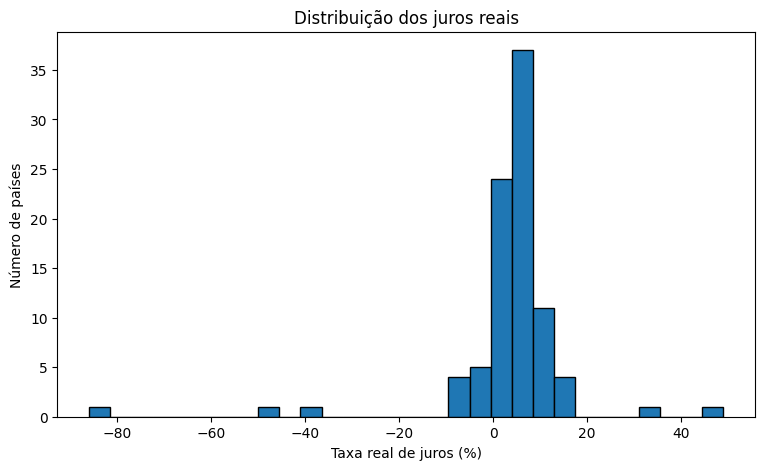

In [16]:
juros_2024.plot(
    kind="hist",
    bins=30,
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Distribuição dos juros reais")
plt.xlabel("Taxa real de juros (%)")
plt.ylabel("Número de países")
plt.show()

### 3.1 Boxplot

O boxplot apresenta mediana, quartis e possíveis valores extremos. Ele é útil para identificar assimetrias e observações que merecem investigação.

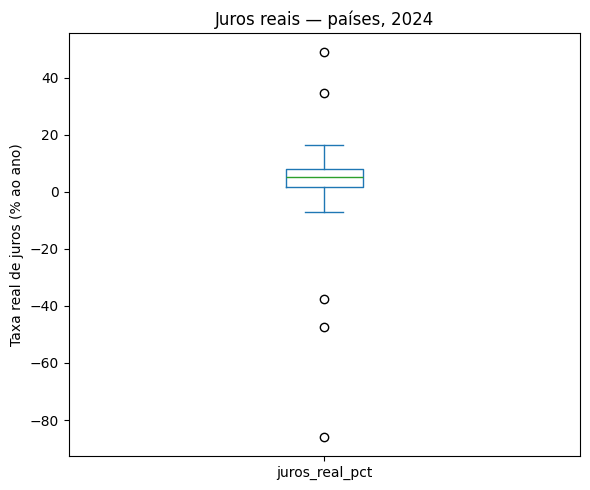

In [11]:
dados_2024[["juros_real_pct"]].plot(
    kind="box", figsize=(6, 5), legend=False
)
plt.title("Juros reais — países, 2024")
plt.ylabel("Taxa real de juros (% ao ano)")
plt.tight_layout()
plt.show()

### 3.2 Gráfico de barras horizontais

O `kind="barh"` produz barras horizontais, úteis para rankings de países.

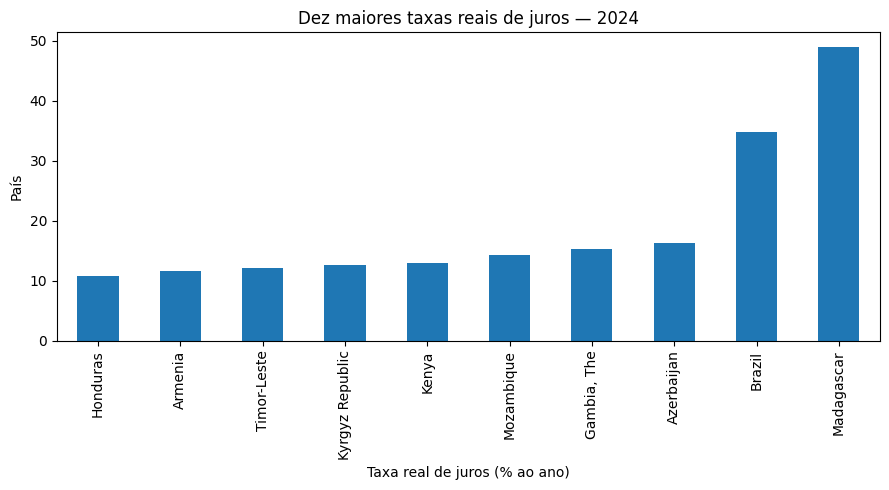

In [13]:
top10_juros = ranking_juros.head(10)

top10_juros.sort_values("juros_real_pct").plot(
    kind="bar", x="pais", y="juros_real_pct",
    figsize=(9, 5), legend=False
)
plt.title("Dez maiores taxas reais de juros — 2024")
plt.xlabel("Taxa real de juros (% ao ano)")
plt.ylabel("País")
plt.tight_layout()
plt.show()

## 4. Evolução temporal dos juros reais

Vamos calcular a média dos países **com observação disponível em cada ano**. Como a cobertura muda, a média mundial simples dos países não representa uma média ponderada pelo tamanho das economias.

,mean,median,count
ano,,,
2015,8.55,6.34,135
2016,6.38,6.23,133
2017,3.71,4.72,127
2018,5.79,5.39,122
2019,6.24,6.54,118
2020,7.08,6.40,113
2021,1.22,2.15,110
2022,-0.76,0.45,99
2023,4.14,3.89,93


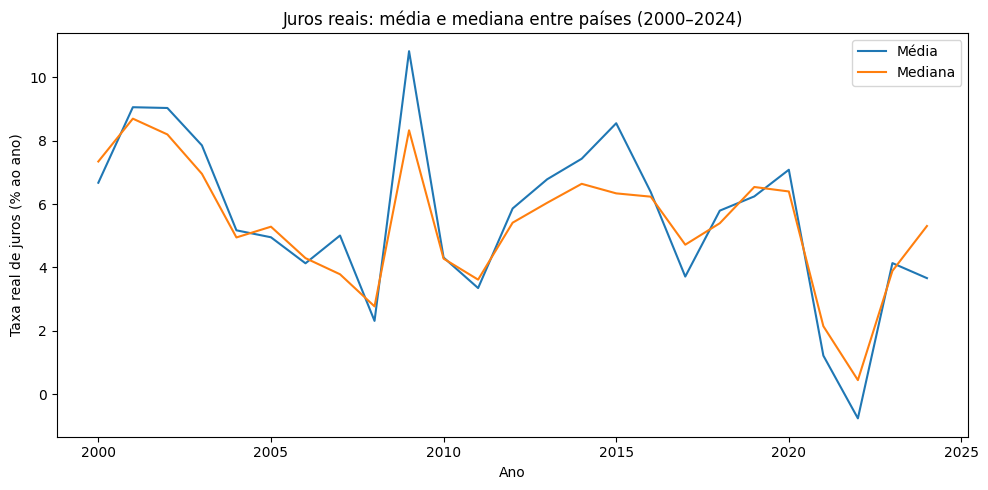

In [14]:
juros_ano = (
    dados.groupby("ano")["juros_real_pct"]
    .agg(["mean", "median", "count"])
)
display(juros_ano.tail(10))

juros_ano[["mean", "median"]].plot(figsize=(10, 5))
plt.title("Juros reais: média e mediana entre países (2000–2024)")
plt.xlabel("Ano")
plt.ylabel("Taxa real de juros (% ao ano)")
plt.legend(["Média", "Mediana"])
plt.tight_layout()
plt.show()

### 4.1 Brasil versus outros países

`isin()` seleciona observações cujo código aparece em uma lista. `pivot()` reorganiza a base de modo que cada país vire uma coluna e cada ano vire uma linha.

codigo_pais,BRA,CHN,MEX,USA,ZAF
ano,,,,,
2020,21.20,3.80,1.65,2.17,2.20
2021,15.01,-0.12,0.39,-1.26,0.60
2022,28.40,2.37,1.42,NaN,3.37
2023,36.55,4.88,6.61,NaN,6.47
2024,34.73,5.15,7.21,NaN,7.42


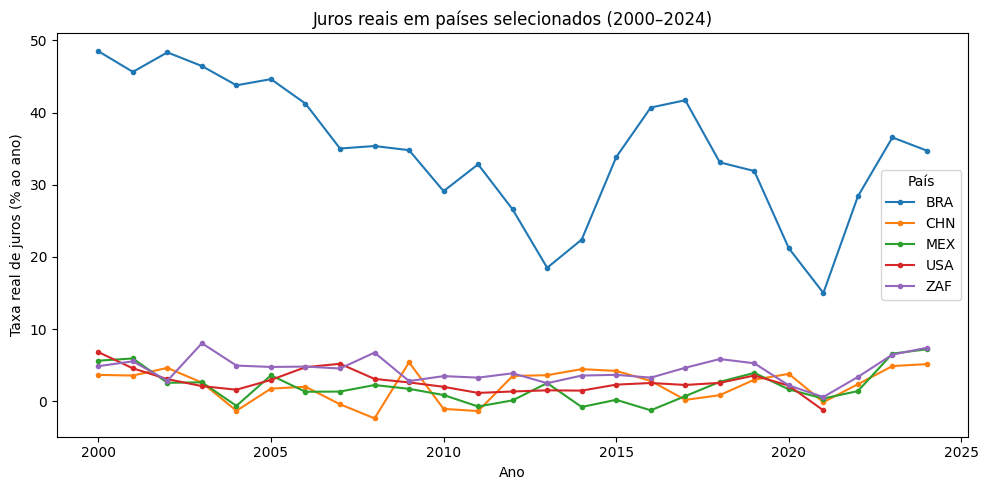

In [26]:
selecionados = ["BRA", "USA", "MEX", "CHN","ZAF"]
comparacao = dados.loc[
    dados["codigo_pais"].isin(selecionados),
    ["ano", "codigo_pais", "juros_real_pct"]
]

series_paises = comparacao.pivot(
    index="ano", columns="codigo_pais", values="juros_real_pct"
)

display(series_paises.tail())
series_paises.plot(figsize=(10, 5), marker="o", markersize=3)
plt.title("Juros reais em países selecionados (2000–2024)")
plt.xlabel("Ano")
plt.ylabel("Taxa real de juros (% ao ano)")
plt.legend(title="País")
plt.tight_layout()
plt.show()

4.2 Brasil versus mediana global

In [45]:
# 1. Calcular a mediana internacional por ano
mediana_ano = (
    dados.groupby("ano", as_index=False)
    .agg(
        juros_mediana=("juros_real_pct", "median")
    )
)

# 2. Selecionar os dados do Brasil
brasil = dados.loc[
    dados["codigo_pais"] == "BRA",
    ["ano", "juros_real_pct"]
]

#display(brasil)
#display(mediana_ano)

type(brasil)

pandas.core.frame.DataFrame

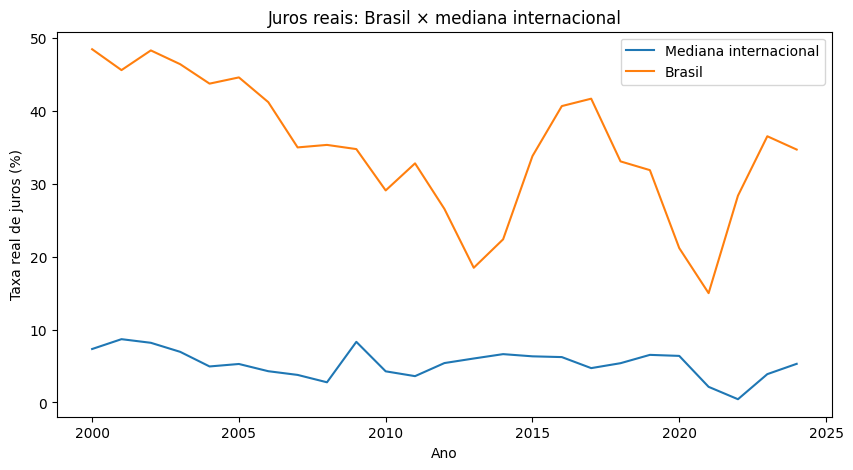

In [46]:
# 3. Construir o gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    mediana_ano["ano"],
    mediana_ano["juros_mediana"],
    label="Mediana internacional"
)

plt.plot(
    brasil["ano"],
    brasil["juros_real_pct"],
    label="Brasil"
)

plt.title("Juros reais: Brasil × mediana internacional")
plt.xlabel("Ano")
plt.ylabel("Taxa real de juros (%)")
plt.legend()
plt.show()

## 5. Correlações e dispersões

`corr()` calcula a correlação de Pearson entre colunas numéricas, utilizando as observações completas disponíveis **para cada par**. `kind="scatter"` desenha pontos de duas variáveis.


In [27]:
variaveis_correlacao = [
    "juros_real_pct", "inflacao_anual_pct",
    "crescimento_pc_pct", "investimento_pct_pib",
    "spread_bancario_pp"
]

# Cálculo da correlação:
matriz = dados_2024[variaveis_correlacao].corr()
display(matriz.round(2))



,juros_real_pct,inflacao_anual_pct,crescimento_pc_pct,investimento_pct_pib,spread_bancario_pp
juros_real_pct,1.00,-0.68,0.11,0.26,0.82
inflacao_anual_pct,-0.68,1.00,-0.18,-0.17,-0.12
crescimento_pc_pct,0.11,-0.18,1.00,0.32,0.04
investimento_pct_pib,0.26,-0.17,0.32,1.00,0.00
spread_bancario_pp,0.82,-0.12,0.04,0.00,1.00


### 5.1 Juros reais e inflação

O gráfico de dispersão utiliza apenas países que possuem os dois valores. Compare-o com a correlação correspondente na matriz.

Países no gráfico: 86


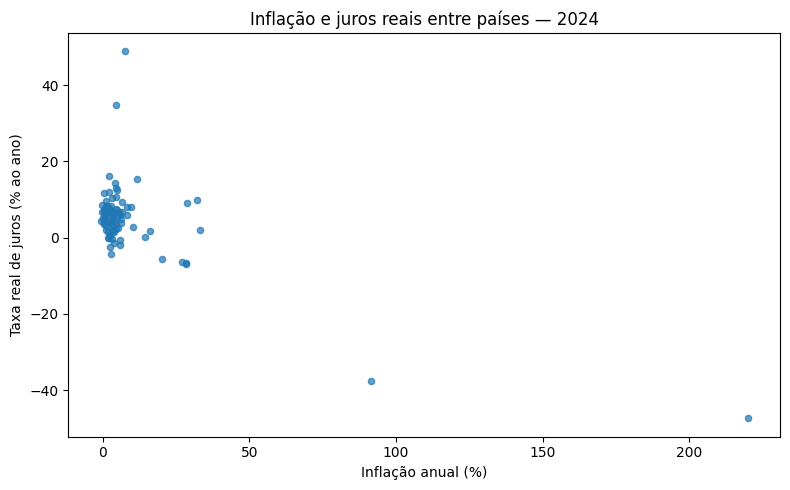

In [22]:
amostra = dados_2024.dropna(
    subset=["juros_real_pct", "inflacao_anual_pct"]
)
print("Países no gráfico:", len(amostra))

amostra.plot(
    kind="scatter", x="inflacao_anual_pct", y="juros_real_pct",
    figsize=(8, 5), alpha=0.7
)
plt.title("Inflação e juros reais entre países — 2024")
plt.xlabel("Inflação anual (%)")
plt.ylabel("Taxa real de juros (% ao ano)")
plt.tight_layout()
plt.show()

Países no gráfico: 73


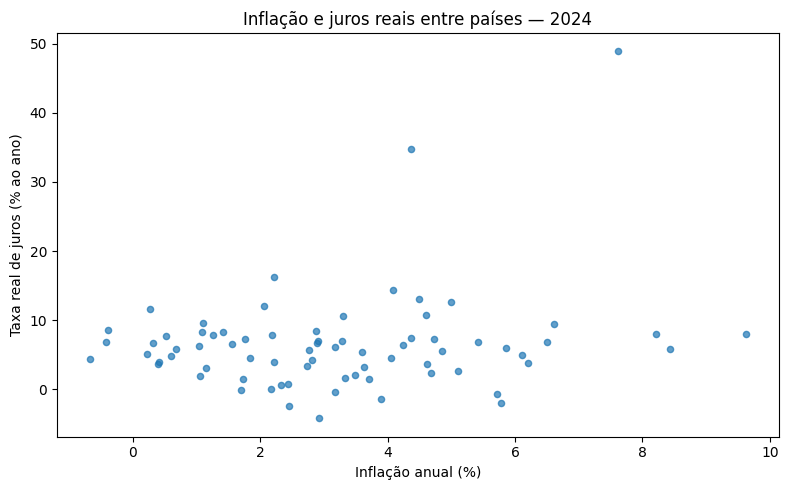

In [28]:
# Selecionar países com inflação até 10%
amostra = dados_2024.loc[
    dados_2024["inflacao_anual_pct"] <= 10
].dropna(
    subset=["juros_real_pct", "inflacao_anual_pct"]
)

print("Países no gráfico:", len(amostra))

# Gráfico de dispersão
amostra.plot(
    kind="scatter",
    x="inflacao_anual_pct",
    y="juros_real_pct",
    figsize=(8, 5),
    alpha=0.7
)

plt.title("Inflação e juros reais entre países — 2024")
plt.xlabel("Inflação anual (%)")
plt.ylabel("Taxa real de juros (% ao ano)")
plt.tight_layout()
plt.show()

### 5.2 Investimento e crescimento econômico



Países no gráfico: 165


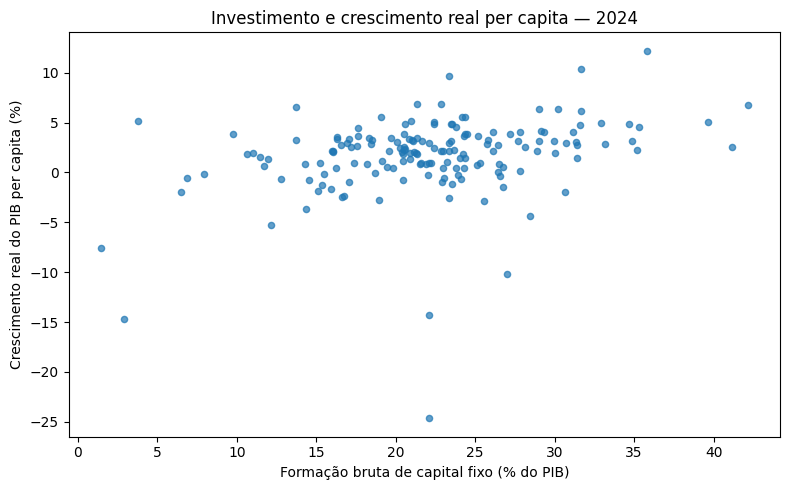

In [23]:
amostra_invest = dados_2024.dropna(
    subset=["investimento_pct_pib", "crescimento_pc_pct"]
)
print("Países no gráfico:", len(amostra_invest))

amostra_invest.plot(
    kind="scatter", x="investimento_pct_pib", y="crescimento_pc_pct",
    figsize=(8, 5), alpha=0.7
)
plt.title("Investimento e crescimento real per capita — 2024")
plt.xlabel("Formação bruta de capital fixo (% do PIB)")
plt.ylabel("Crescimento real do PIB per capita (%)")
plt.tight_layout()
plt.show()

### 5.3 Heatmap simples com Matplotlib

`imshow()` transforma a matriz numérica em uma imagem colorida. `colorbar()` inclui a escala; `xticks()` e `yticks()` mostram os nomes das variáveis. Não é necessário aprender uma biblioteca adicional.

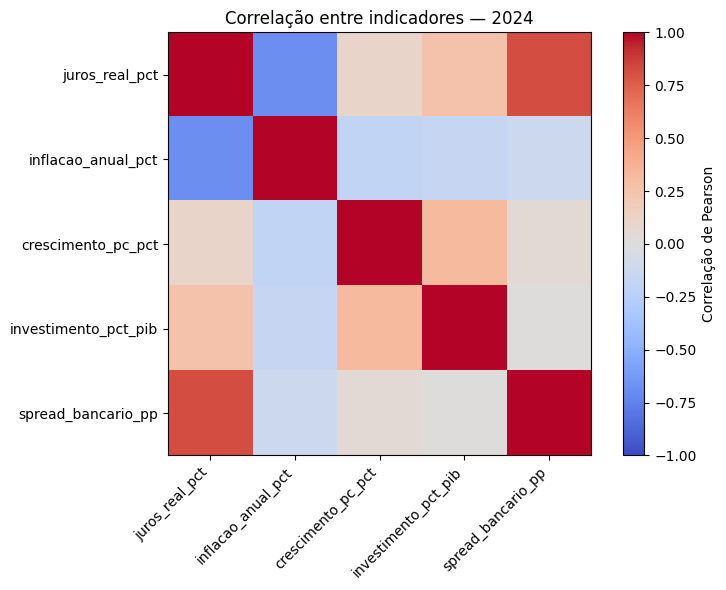

In [24]:
fig, ax = plt.subplots(figsize=(8, 6))
imagem = ax.imshow(matriz, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(variaveis_correlacao)))
ax.set_yticks(range(len(variaveis_correlacao)))
ax.set_xticklabels(variaveis_correlacao, rotation=45, ha="right")
ax.set_yticklabels(variaveis_correlacao)
fig.colorbar(imagem, ax=ax, label="Correlação de Pearson")
ax.set_title("Correlação entre indicadores — 2024")
plt.tight_layout()
plt.show()

### 5.4 Regressão linear simples em gráfico com seaborn e  scipy.stats

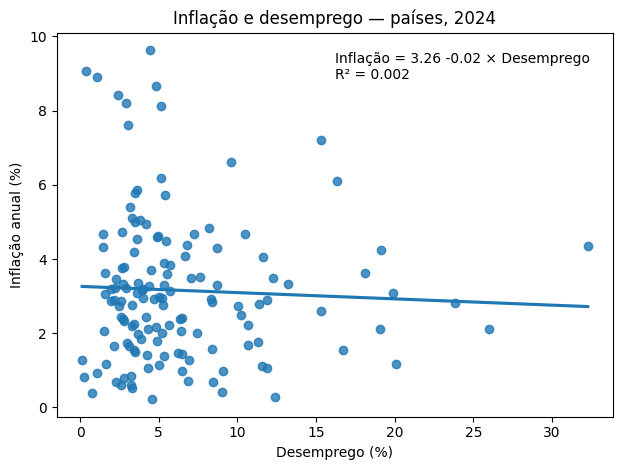

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Selecionar países com inflação entre 0% e 10%
amostra = dados_2024.loc[
    dados_2024["inflacao_anual_pct"].between(0, 10)
].dropna(subset=["inflacao_anual_pct", "desemprego_pct"])

# Estimar coeficientes
resultado = linregress(
    amostra["desemprego_pct"],
    amostra["inflacao_anual_pct"]
)

# Gráfico com reta de regressão automática
sns.regplot(
    data=amostra,
    x="desemprego_pct",
    y="inflacao_anual_pct",
    ci=None
)

plt.title("Inflação e desemprego — países, 2024")
plt.xlabel("Desemprego (%)")
plt.ylabel("Inflação anual (%)")

# Equação e R²
plt.text(
    0.5, 0.95,
    f"Inflação = {resultado.intercept:.2f} "
    f"{resultado.slope:+.2f} × Desemprego\n"
    f"R² = {resultado.rvalue**2:.3f}",
    transform=plt.gca().transAxes,
    va="top"
)

plt.tight_layout()
plt.show()

## 6. Exercícios em sala

Trabalhe com os objetos `dados` (painel 2000–2024) e `dados_2024` (países em 2024).

### Exercício 1 — Estatísticas descritivas

Calcule média, mediana, desvio-padrão, mínimo, máximo e número de observações dos juros reais em 2024. A média parece representativa?

In [ ]:
# Exercício 1
# Escreva seu código aqui.

### Exercício 2 — Ranking

Identifique os dez países com maiores juros reais em 2024, exibindo país e taxa. E os dez menores?

In [ ]:
# Exercício 2
# Escreva seu código aqui.

### Exercício 3 — Distribuição

Construa um histograma com 20 intervalos e um boxplot para investimento em % do PIB em 2024. (investimento_pct_pib)

In [ ]:
# Exercício 3
# Escreva seu código aqui.

### Exercício 4 — Brasil e comparação internacional

Calcule a trajetória da mediana de investimento em % do PIB entre os países por ano e represente-a junto à trajetória brasileira em um único gráfico.

In [ ]:
# Exercício 4
# Escreva seu código aqui.

### Exercício 5 — Dispersão

Construa o gráfico de dispersão de investimento (% do PIB) contra crescimento real per capita (%) em 2024. Dê título e nomes apropriados aos eixos.

In [ ]:
# Exercício 6
# Escreva seu código aqui.

# Variáveis de interesse
variaveis = [
    "investimento_pct_pib",
    "crescimento_pc_pct"
]

### Exercício 6 — Análise econômica

Compare as correlações de renda de recursos naturais (% do PIB obtido da extração de recursos naturais), com PIB per capita e cresicmento do PIB em 2021.

Ano selecionado: 2021
Países com informações: 197


In [36]:
# Exercício 7
# Escreva seu código aqui.

# Variáveis de interesse
variaveis = [
    "rendas_recursos_pct_pib",
    "investimento_pct_pib",
    "pib_per_capita_usd",
    "crescimento_pc_pct"
]


## 7. Conclusões e continuidade

Nesta aula utilizamos o Python para **inspecionar**, **resumir**, **visualizar** e **comparar** dados econômicos internacionais. Na próxima aula, os mesmos indicadores poderão  vão ser usados em uma estimação por MQO

### Fontes e documentação

- [API do Banco Mundial — documentação oficial](https://datahelpdesk.worldbank.org/knowledgebase/articles/889392-about-the-indicators-api-documentation)
- [Consultas de países e regiões — documentação oficial](https://datahelpdesk.worldbank.org/knowledgebase/articles/898590-country-api-queries)
- [World Development Indicators](https://databank.worldbank.org/source/world-development-indicators)
- [Pandas — documentação](https://pandas.pydata.org/docs/)
- [Matplotlib — documentação](https://matplotlib.org/stable/)

